# Joint BiLSTM — readable, explained learning notebook

**Goal:** Study how one BiLSTM can predict both the intent of a sentence and its slot spans from the MASSIVE English dataset.

**Academic integrity:** This notebook is AI-generated learning material. Your assignment requires Stage 1 to be developed without generative AI assistance; do not claim this notebook as independently authored Stage 1 work. You can use it as a conceptual reference and for the AI-permitted Stage 2.

**How to use:** Place `en-US.jsonl` in the same folder as this notebook, choose your Python kernel, and run the cells top to bottom. Every important code block has an explanation before it.

**Naming guide:** `training_records`, `validation_records`, `test_records` are dataset lists; `word_to_id`, `intent_to_id`, `slot_to_id` are dictionaries; `token_offsets` are `(word, start, end)` triples; `slot_spans` are `(slot_type, start, end)` triples.

## 1. Import libraries and configure the experiment

We use **PyTorch** for the model, **Counter** to count words and slot matches, and **Matplotlib** to plot the learning curves. A random seed makes repeated experiments more comparable. `device` selects your NVIDIA GPU if CUDA is working, otherwise the CPU.

In [1]:
import json
import random
import re
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
data_file_path = Path("en-US.jsonl")
checkpoint_file_path = Path("bilstm_joint_best.pt")

print("Python will run the model on:", device)
print("PyTorch version:", torch.__version__)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Python will run the model on: cuda
PyTorch version: 2.11.0+cu128
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


## 2. Load the official MASSIVE English dataset

Each line in `en-US.jsonl` is a JSON object. The file already contains `train`, `dev`, and `test` partitions. **Never re-split or train on the validation/test partitions.** This section reads the file and checks the required example counts.

In [2]:
if not data_file_path.exists():
    raise FileNotFoundError(
        f"Cannot find {data_file_path}. Put en-US.jsonl beside this notebook."
    )

with data_file_path.open("r", encoding="utf-8") as data_file:
    all_records = [json.loads(line) for line in data_file if line.strip()]

training_records = [record for record in all_records if record["partition"] == "train"]
validation_records = [record for record in all_records if record["partition"] == "dev"]
test_records = [record for record in all_records if record["partition"] == "test"]

print("Training examples:", len(training_records))
print("Validation examples:", len(validation_records))
print("Test examples:", len(test_records))

assert len(training_records) == 11514
assert len(validation_records) == 2033
assert len(test_records) == 2974
assert len(all_records) == 16521
assert all(record["locale"] == "en-US" for record in all_records)

print("Example input:", training_records[0]["utt"])
print("Example intent:", training_records[0]["intent"])
print("Example annotation:", training_records[0]["annot_utt"])

Training examples: 11514
Validation examples: 2033
Test examples: 2974
Example input: wake me up at nine am on friday
Example intent: alarm_set
Example annotation: wake me up at [time : nine am] on [date : friday]


## 3. Understand slot annotations and character offsets

The annotated sentence `wake ... [time : five am]` contains a slot type (`time`) and its exact text (`five am`). We remove the brackets while recording the **start and end character positions** of each slot. This matters because evaluation requires exact text spans.

`tokenize_with_offsets` uses whitespace-separated tokens. For example, `nine` could be represented as `("nine", 14, 18)`. The indices follow normal Python slicing: `text[start:end]`.

`convert_spans_to_bio` converts slot spans into token labels such as `B-time`, `I-time`, and `O`. It raises an error if a slot cannot be aligned with the tokens.

In [3]:
slot_annotation_pattern = re.compile(r"\[([^:\]]+)\s*:\s*([^\]]+)\]")
word_pattern = re.compile(r"\S+")


def parse_annotated_utterance(annotated_utterance):
    original_text_parts = []
    slot_spans = []
    current_character_position = 0
    previous_match_end = 0

    for annotation_match in slot_annotation_pattern.finditer(annotated_utterance):
        text_before_slot = annotated_utterance[previous_match_end:annotation_match.start()]
        original_text_parts.append(text_before_slot)
        current_character_position += len(text_before_slot)

        slot_type = annotation_match.group(1).strip()
        slot_text = annotation_match.group(2)
        slot_start = current_character_position
        slot_end = slot_start + len(slot_text)

        original_text_parts.append(slot_text)
        slot_spans.append((slot_type, slot_start, slot_end))
        current_character_position = slot_end
        previous_match_end = annotation_match.end()

    original_text_parts.append(annotated_utterance[previous_match_end:])
    original_text = "".join(original_text_parts)
    return original_text, slot_spans


def tokenize_with_offsets(utterance):
    token_offsets = []
    for token_match in word_pattern.finditer(utterance):
        token_offsets.append((token_match.group(), token_match.start(), token_match.end()))
    return token_offsets


def convert_spans_to_bio(token_offsets, slot_spans):
    bio_labels = ["O"] * len(token_offsets)

    for slot_type, slot_start, slot_end in slot_spans:
        matching_token_indices = []
        for token_index, (token, token_start, token_end) in enumerate(token_offsets):
            if token_start < slot_end and token_end > slot_start:
                matching_token_indices.append(token_index)

        if not matching_token_indices:
            raise ValueError(f"No token found for slot {slot_type} at {slot_start}:{slot_end}")

        first_token_index = matching_token_indices[0]
        last_token_index = matching_token_indices[-1]
        first_token_start = token_offsets[first_token_index][1]
        last_token_end = token_offsets[last_token_index][2]

        if first_token_start != slot_start or last_token_end != slot_end:
            raise ValueError(f"Slot is not aligned with token boundaries: {slot_type}")

        if any(bio_labels[token_index] != "O" for token_index in matching_token_indices):
            raise ValueError("Overlapping slot annotations are not supported")

        bio_labels[first_token_index] = f"B-{slot_type}"
        for token_index in matching_token_indices[1:]:
            bio_labels[token_index] = f"I-{slot_type}"

    return bio_labels


sample_record = training_records[0]
sample_text, sample_slot_spans = parse_annotated_utterance(sample_record["annot_utt"])
sample_tokens = tokenize_with_offsets(sample_text)
sample_bio_labels = convert_spans_to_bio(sample_tokens, sample_slot_spans)

print("Original sentence:", sample_text)
print("Tokens:", [token for token, start, end in sample_tokens])
print("BIO labels:", sample_bio_labels)
print("Slot spans:", [(slot_type, sample_text[start:end]) for slot_type, start, end in sample_slot_spans])

Original sentence: wake me up at nine am on friday
Tokens: ['wake', 'me', 'up', 'at', 'nine', 'am', 'on', 'friday']
BIO labels: ['O', 'O', 'O', 'O', 'B-time', 'I-time', 'O', 'B-date']
Slot spans: [('time', 'nine am'), ('date', 'friday')]


## 4. Verify annotations before training

Parsing errors are much easier to fix before training. This cell checks that removing annotations reproduces the original utterance and that each gold slot aligns exactly with the tokenizer. **Do not delete failing records:** investigate any reported mismatch.

In [4]:
dataset_partitions = {
    "train": training_records,
    "dev": validation_records,
    "test": test_records,
}

for partition_name, records in dataset_partitions.items():
    for record in records:
        reconstructed_text, slot_spans = parse_annotated_utterance(record["annot_utt"])
        assert reconstructed_text == record["utt"], (
            f"Text mismatch: {partition_name}, record {record['id']}"
        )
        token_offsets = tokenize_with_offsets(record["utt"])
        convert_spans_to_bio(token_offsets, slot_spans)

print("Every annotation was reconstructed and aligned successfully.")

Every annotation was reconstructed and aligned successfully.


## 5. Build word, intent, and slot dictionaries

Neural networks work with numeric IDs, not strings. A *vocabulary* gives each word an integer ID. `<PAD>` fills shorter sequences in a batch; `<UNK>` represents a word absent from training.

We collect **word frequencies and known slot types from training only**. A BIO classifier requires both `B-` and `I-` for every slot type, even if one variant never appeared in training. This avoids the previously encountered missing `I-...` label assertion. We still check held-out records for unknown labels instead of silently adding test-only categories.

In [5]:
word_frequencies = Counter()
known_intent_labels = set()
known_slot_types = set()

for record in training_records:
    token_offsets = tokenize_with_offsets(record["utt"])
    for token, token_start, token_end in token_offsets:
        word_frequencies[token.lower()] += 1

    known_intent_labels.add(record["intent"])
    original_text, slot_spans = parse_annotated_utterance(record["annot_utt"])
    for slot_type, slot_start, slot_end in slot_spans:
        known_slot_types.add(slot_type)

word_to_id = {"<PAD>": 0, "<UNK>": 1}
for word in sorted(word_frequencies):
    word_to_id[word] = len(word_to_id)

intent_to_id = {}
for intent_index, intent_label in enumerate(sorted(known_intent_labels)):
    intent_to_id[intent_label] = intent_index

bio_label_names = {"O"}
for slot_type in known_slot_types:
    bio_label_names.add(f"B-{slot_type}")
    bio_label_names.add(f"I-{slot_type}")

slot_to_id = {}
for slot_index, slot_label in enumerate(sorted(bio_label_names)):
    slot_to_id[slot_label] = slot_index

id_to_intent = {intent_index: intent_label for intent_label, intent_index in intent_to_id.items()}
id_to_slot = {slot_index: slot_label for slot_label, slot_index in slot_to_id.items()}

print("Vocabulary size:", len(word_to_id))
print("Intent classes:", len(intent_to_id))
print("Slot types:", len(known_slot_types))
print("BIO classes:", len(slot_to_id))
assert len(intent_to_id) == 60

for partition_name in ("dev", "test"):
    for record in dataset_partitions[partition_name]:
        if record["intent"] not in intent_to_id:
            raise ValueError(f"Unknown intent in {partition_name}: {record['intent']}")

        original_text, slot_spans = parse_annotated_utterance(record["annot_utt"])
        bio_labels = convert_spans_to_bio(tokenize_with_offsets(original_text), slot_spans)
        unknown_bio_labels = [label for label in bio_labels if label not in slot_to_id]
        if unknown_bio_labels:
            raise ValueError(
                f"Unknown slot tags in {partition_name} record {record['id']}: {unknown_bio_labels}"
            )

print("All dev and test labels are covered by the training-derived label mappings.")

Vocabulary size: 5304
Intent classes: 60
Slot types: 55
BIO classes: 111
All dev and test labels are covered by the training-derived label mappings.


## 6. Convert records into examples and create padded batches

A `Dataset` converts one utterance into input word IDs, intent ID, and slot BIO IDs. A `DataLoader` collects many examples into a batch.

Sentences have different lengths, so `prepare_batch` pads them to the longest sentence in that batch. **0** is our word padding ID; **-100** is our slot padding target, which PyTorch's cross-entropy can ignore. We also keep the original text and token offsets for exact-span evaluation.

In [6]:
class MassiveJointDataset(Dataset):
    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, record_index):
        record = self.records[record_index]
        utterance = record["utt"]
        token_offsets = tokenize_with_offsets(utterance)
        original_text, slot_spans = parse_annotated_utterance(record["annot_utt"])
        bio_labels = convert_spans_to_bio(token_offsets, slot_spans)

        word_ids = [word_to_id.get(token.lower(), word_to_id["<UNK>"])
                    for token, token_start, token_end in token_offsets]
        slot_ids = [slot_to_id[label] for label in bio_labels]
        gold_slot_pairs = [(slot_type, utterance[start:end])
                           for slot_type, start, end in slot_spans]

        return {
            "word_ids": word_ids,
            "intent_id": intent_to_id[record["intent"]],
            "slot_ids": slot_ids,
            "utterance": utterance,
            "token_offsets": [(start, end) for token, start, end in token_offsets],
            "gold_slot_pairs": gold_slot_pairs,
        }


def prepare_batch(examples):
    sequence_lengths = torch.tensor([len(example["word_ids"]) for example in examples])
    if not torch.all(sequence_lengths > 0):
        raise ValueError("Empty utterances are not supported")

    batch_size = len(examples)
    longest_sequence_length = int(sequence_lengths.max().item())
    padded_word_ids = torch.zeros(batch_size, longest_sequence_length, dtype=torch.long)
    padded_slot_ids = torch.full(
        (batch_size, longest_sequence_length), fill_value=-100, dtype=torch.long
    )

    for example_index, example in enumerate(examples):
        sequence_length = len(example["word_ids"])
        padded_word_ids[example_index, :sequence_length] = torch.tensor(example["word_ids"])
        padded_slot_ids[example_index, :sequence_length] = torch.tensor(example["slot_ids"])

    return {
        "word_ids": padded_word_ids,
        "slot_ids": padded_slot_ids,
        "intent_ids": torch.tensor([example["intent_id"] for example in examples]),
        "sequence_lengths": sequence_lengths,
        "utterances": [example["utterance"] for example in examples],
        "token_offsets": [example["token_offsets"] for example in examples],
        "gold_slot_pairs": [example["gold_slot_pairs"] for example in examples],
    }

batch_size = 64
training_loader = DataLoader(MassiveJointDataset(training_records), batch_size=batch_size,
                             shuffle=True, collate_fn=prepare_batch)
validation_loader = DataLoader(MassiveJointDataset(validation_records), batch_size=batch_size,
                               shuffle=False, collate_fn=prepare_batch)
test_loader = DataLoader(MassiveJointDataset(test_records), batch_size=batch_size,
                         shuffle=False, collate_fn=prepare_batch)

sample_batch = next(iter(training_loader))
print("Word IDs shape:", tuple(sample_batch["word_ids"].shape))
print("Slot labels shape:", tuple(sample_batch["slot_ids"].shape))
print("Intent labels shape:", tuple(sample_batch["intent_ids"].shape))

Word IDs shape: (64, 15)
Slot labels shape: (64, 15)
Intent labels shape: (64,)


## 7. Define the shared BiLSTM model

1. **Embedding:** turns each word ID into a vector.
2. **BiLSTM encoder:** processes the sentence from left to right and right to left. Because each direction has `hidden_size` values, every token has `2 × hidden_size` output features.
3. **Intent head:** averages the real token representations and predicts one of 60 intents.
4. **Slot head:** predicts a BIO label for **each token**.

`pack_padded_sequence` prevents padding from being treated as real words. The two output heads **share** the BiLSTM encoder, so this is one joint model.

In [7]:
class JointBiLSTM(nn.Module):
    def __init__(self, vocabulary_size, number_of_intents, number_of_slot_labels,
                 embedding_size=128, hidden_size=128, dropout_probability=0.3):
        super().__init__()

        self.word_embedding = nn.Embedding(
            num_embeddings=vocabulary_size,
            embedding_dim=embedding_size,
            padding_idx=word_to_id["<PAD>"],
        )
        self.bilstm_encoder = nn.LSTM(
            input_size=embedding_size,
            hidden_size=hidden_size,
            num_layers=1,
            bidirectional=True,
            batch_first=True,
        )
        self.dropout = nn.Dropout(dropout_probability)
        self.intent_classifier = nn.Linear(hidden_size * 2, number_of_intents)
        self.slot_classifier = nn.Linear(hidden_size * 2, number_of_slot_labels)

    def forward(self, word_ids, sequence_lengths):
        word_vectors = self.dropout(self.word_embedding(word_ids))
        packed_word_vectors = pack_padded_sequence(
            word_vectors, sequence_lengths.cpu(),
            batch_first=True, enforce_sorted=False,
        )
        packed_encoded_tokens, _ = self.bilstm_encoder(packed_word_vectors)
        encoded_tokens, _ = pad_packed_sequence(
            packed_encoded_tokens, batch_first=True,
            total_length=word_ids.size(1),
        )

        token_positions = torch.arange(word_ids.size(1), device=word_ids.device)
        real_token_mask = token_positions.unsqueeze(0) < sequence_lengths.to(word_ids.device).unsqueeze(1)
        summed_token_features = (encoded_tokens * real_token_mask.unsqueeze(-1)).sum(dim=1)
        sentence_features = summed_token_features / sequence_lengths.to(word_ids.device).unsqueeze(1)

        intent_scores = self.intent_classifier(self.dropout(sentence_features))
        slot_scores = self.slot_classifier(self.dropout(encoded_tokens))
        return intent_scores, slot_scores


model_settings = {
    "vocabulary_size": len(word_to_id),
    "number_of_intents": len(intent_to_id),
    "number_of_slot_labels": len(slot_to_id),
    "embedding_size": 128,
    "hidden_size": 128,
    "dropout_probability": 0.3,
}

model = JointBiLSTM(**model_settings).to(device)
model_parameter_count = sum(parameter.numel() for parameter in model.parameters())
print("Total model parameters (including word embeddings):", f"{model_parameter_count:,}")
assert model_parameter_count <= 20_000_000

with torch.no_grad():
    example_intent_scores, example_slot_scores = model(
        sample_batch["word_ids"].to(device), sample_batch["sequence_lengths"]
    )
print("Intent output shape:", tuple(example_intent_scores.shape))
print("Slot output shape:", tuple(example_slot_scores.shape))

Total model parameters (including word embeddings): 987,051
Intent output shape: (64, 60)
Slot output shape: (64, 15, 111)


## 8. Define the loss and reconstruct predicted slot spans

Both outputs use cross-entropy loss. The total loss is `intent_loss + slot_loss_weight × slot_loss`. For slot loss, PyTorch ignores the `-100` padding labels.

For evaluation, `decode_slot_spans` converts token-level BIO labels back into the exact substring of the original utterance. We count a slot as correct only if **both the slot type and the extracted text match**. Micro-F1 combines true positives, false positives and false negatives across all examples.

In [8]:
intent_loss_function = nn.CrossEntropyLoss()
slot_loss_function = nn.CrossEntropyLoss(ignore_index=-100)
slot_loss_weight = 1.0


def calculate_joint_loss(intent_scores, slot_scores, actual_intent_ids, actual_slot_ids):
    intent_loss = intent_loss_function(intent_scores, actual_intent_ids)
    slot_loss = slot_loss_function(slot_scores.transpose(1, 2), actual_slot_ids)
    return intent_loss + slot_loss_weight * slot_loss


def decode_slot_spans(predicted_bio_labels, token_offsets, utterance):
    predicted_slot_pairs = []
    current_slot_type = None
    current_slot_start = None
    current_slot_end = None

    def finish_current_slot():
        if current_slot_type is not None:
            predicted_slot_pairs.append((
                current_slot_type, utterance[current_slot_start:current_slot_end]
            ))

    for bio_label, (token_start, token_end) in zip(predicted_bio_labels, token_offsets):
        if bio_label == "O":
            finish_current_slot()
            current_slot_type = None
            current_slot_start = None
            current_slot_end = None
            continue

        bio_prefix, slot_type = bio_label.split("-", 1)
        if bio_prefix == "B" or current_slot_type != slot_type:
            finish_current_slot()
            current_slot_type = slot_type
            current_slot_start = token_start
            current_slot_end = token_end
        else:
            current_slot_end = token_end

    finish_current_slot()
    return predicted_slot_pairs


def count_slot_matches(predicted_slot_pairs, gold_slot_pairs):
    predicted_counts = Counter(predicted_slot_pairs)
    gold_counts = Counter(gold_slot_pairs)
    true_positives = sum((predicted_counts & gold_counts).values())
    false_positives = sum(predicted_counts.values()) - true_positives
    false_negatives = sum(gold_counts.values()) - true_positives
    return true_positives, false_positives, false_negatives


def calculate_evaluation_percentages(correct_intent_count, example_count,
                                     true_positives, false_positives, false_negatives):
    intent_accuracy = 100 * correct_intent_count / example_count
    denominator = 2 * true_positives + false_positives + false_negatives
    slot_micro_f1 = 100 * (2 * true_positives) / denominator if denominator else 100.0
    return intent_accuracy, slot_micro_f1


print(decode_slot_spans(
    ["O", "B-time", "I-time", "O"],
    [(0, 4), (5, 9), (10, 12), (13, 15)],
    "wake nine am on",
))

[('time', 'nine am')]


## 9. Train one epoch and evaluate one dataset

**Training** updates model weights: (1) move tensors to GPU/CPU, (2) predict, (3) calculate loss, (4) backpropagate, (5) update weights. **Evaluation** never changes weights; it decodes slot spans and computes both assignment metrics.

Names such as `predicted_intent_ids` and `true_positive_count` deliberately describe their meaning rather than using single letters.

In [9]:
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.0001)


def train_for_one_epoch(model, data_loader):
    model.train()
    weighted_loss_total = 0.0
    example_count = 0

    for batch in data_loader:
        word_ids = batch["word_ids"].to(device)
        actual_intent_ids = batch["intent_ids"].to(device)
        actual_slot_ids = batch["slot_ids"].to(device)

        optimizer.zero_grad()
        intent_scores, slot_scores = model(word_ids, batch["sequence_lengths"])
        batch_loss = calculate_joint_loss(
            intent_scores, slot_scores, actual_intent_ids, actual_slot_ids
        )
        batch_loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        current_batch_size = word_ids.size(0)
        weighted_loss_total += batch_loss.item() * current_batch_size
        example_count += current_batch_size

    return weighted_loss_total / example_count


@torch.no_grad()
def evaluate_model(model, data_loader):
    model.eval()
    weighted_loss_total = 0.0
    example_count = 0
    correct_intent_count = 0
    true_positive_count = 0
    false_positive_count = 0
    false_negative_count = 0
    example_errors = []

    for batch in data_loader:
        word_ids = batch["word_ids"].to(device)
        actual_intent_ids = batch["intent_ids"].to(device)
        actual_slot_ids = batch["slot_ids"].to(device)
        intent_scores, slot_scores = model(word_ids, batch["sequence_lengths"])

        batch_loss = calculate_joint_loss(
            intent_scores, slot_scores, actual_intent_ids, actual_slot_ids
        )
        weighted_loss_total += batch_loss.item() * word_ids.size(0)

        predicted_intent_ids = intent_scores.argmax(dim=-1).cpu().tolist()
        predicted_slot_id_sequences = slot_scores.argmax(dim=-1).cpu().tolist()
        gold_intent_ids = batch["intent_ids"].tolist()

        for example_index, predicted_intent_id in enumerate(predicted_intent_ids):
            example_count += 1
            actual_intent_id = gold_intent_ids[example_index]
            if predicted_intent_id == actual_intent_id:
                correct_intent_count += 1

            actual_token_count = int(batch["sequence_lengths"][example_index])
            predicted_slot_ids = predicted_slot_id_sequences[example_index][:actual_token_count]
            predicted_bio_labels = [id_to_slot[slot_id] for slot_id in predicted_slot_ids]
            utterance = batch["utterances"][example_index]
            token_offsets = batch["token_offsets"][example_index]
            predicted_slot_pairs = decode_slot_spans(predicted_bio_labels, token_offsets, utterance)
            gold_slot_pairs = batch["gold_slot_pairs"][example_index]

            true_positives, false_positives, false_negatives = count_slot_matches(
                predicted_slot_pairs, gold_slot_pairs
            )
            true_positive_count += true_positives
            false_positive_count += false_positives
            false_negative_count += false_negatives

            has_incorrect_intent = predicted_intent_id != actual_intent_id
            has_incorrect_slots = Counter(predicted_slot_pairs) != Counter(gold_slot_pairs)
            if (has_incorrect_intent or has_incorrect_slots) and len(example_errors) < 20:
                example_errors.append({
                    "utterance": utterance,
                    "correct_intent": id_to_intent[actual_intent_id],
                    "predicted_intent": id_to_intent[predicted_intent_id],
                    "correct_slots": gold_slot_pairs,
                    "predicted_slots": predicted_slot_pairs,
                })

    intent_accuracy, slot_micro_f1 = calculate_evaluation_percentages(
        correct_intent_count, example_count,
        true_positive_count, false_positive_count, false_negative_count,
    )
    return {
        "loss": weighted_loss_total / example_count,
        "intent_accuracy": intent_accuracy,
        "slot_micro_f1": slot_micro_f1,
        "errors": example_errors,
    }

## 10. Run training and save the best checkpoint

An **epoch** means one full pass over training data. After every epoch we measure validation performance and save the checkpoint with the highest mean of validation intent accuracy and exact-span slot micro-F1. The test set is **not** involved in selecting the best model.

Set `number_of_epochs` based on your experiment. Training may be significantly slower on CPU. The cell records the real per-epoch losses, metrics, and elapsed seconds.

In [12]:
number_of_epochs = 12
training_history = []
best_validation_score = float("-inf")
best_epoch_number = None

for epoch_number in range(1, number_of_epochs + 1):
    epoch_start_time = time.perf_counter()

    training_loss = train_for_one_epoch(model, training_loader)
    validation_results = evaluate_model(model, validation_loader)
    combined_validation_score = (
        validation_results["intent_accuracy"] + validation_results["slot_micro_f1"]
    ) / 2
    elapsed_seconds = time.perf_counter() - epoch_start_time

    training_history.append({
        "epoch": epoch_number,
        "training_loss": training_loss,
        "validation_loss": validation_results["loss"],
        "intent_accuracy": validation_results["intent_accuracy"],
        "slot_micro_f1": validation_results["slot_micro_f1"],
        "combined_score": combined_validation_score,
        "seconds": elapsed_seconds,
    })

    print(
        f"Epoch {epoch_number:02d} | train loss: {training_loss:.4f} "
        f"| dev loss: {validation_results['loss']:.4f} "
        f"| intent: {validation_results['intent_accuracy']:.2f}% "
        f"| slot F1: {validation_results['slot_micro_f1']:.2f}% "
        f"| combined: {combined_validation_score:.2f} "
        f"| time: {elapsed_seconds:.1f}s"
    )

    if combined_validation_score > best_validation_score:
        best_validation_score = combined_validation_score
        best_epoch_number = epoch_number

        torch.save({
            "model_weights": model.state_dict(),
            "model_settings": model_settings,
            "word_to_id": word_to_id,
            "intent_to_id": intent_to_id,
            "slot_to_id": slot_to_id,
            "best_epoch": best_epoch_number,
            "best_validation_score": best_validation_score,
        }, checkpoint_file_path)

print("Saved checkpoint:", checkpoint_file_path)
print("Best epoch:", best_epoch_number)
print(f"Best validation score: {best_validation_score:.2f}")

Epoch 01 | train loss: 0.3781 | dev loss: 1.0705 | intent: 84.80% | slot F1: 70.59% | combined: 77.70 | time: 6.3s
Epoch 02 | train loss: 0.3614 | dev loss: 1.0816 | intent: 84.75% | slot F1: 70.49% | combined: 77.62 | time: 6.2s
Epoch 03 | train loss: 0.3538 | dev loss: 1.0744 | intent: 84.65% | slot F1: 70.60% | combined: 77.63 | time: 6.5s
Epoch 04 | train loss: 0.3352 | dev loss: 1.0841 | intent: 85.19% | slot F1: 70.54% | combined: 77.87 | time: 6.4s
Epoch 05 | train loss: 0.3236 | dev loss: 1.0883 | intent: 84.95% | slot F1: 70.69% | combined: 77.82 | time: 7.3s
Epoch 06 | train loss: 0.3075 | dev loss: 1.0925 | intent: 85.05% | slot F1: 70.47% | combined: 77.76 | time: 7.0s
Epoch 07 | train loss: 0.2934 | dev loss: 1.0987 | intent: 85.05% | slot F1: 71.06% | combined: 78.05 | time: 6.1s
Epoch 08 | train loss: 0.2898 | dev loss: 1.1242 | intent: 85.15% | slot F1: 71.09% | combined: 78.12 | time: 6.1s
Epoch 09 | train loss: 0.2855 | dev loss: 1.1361 | intent: 84.85% | slot F1: 71.

## 11. Plot the learning curves

The loss plot helps identify overfitting. The second plot lets you see whether intent accuracy and slot F1 improve together. These figures come from recorded history, not manually typed scores.

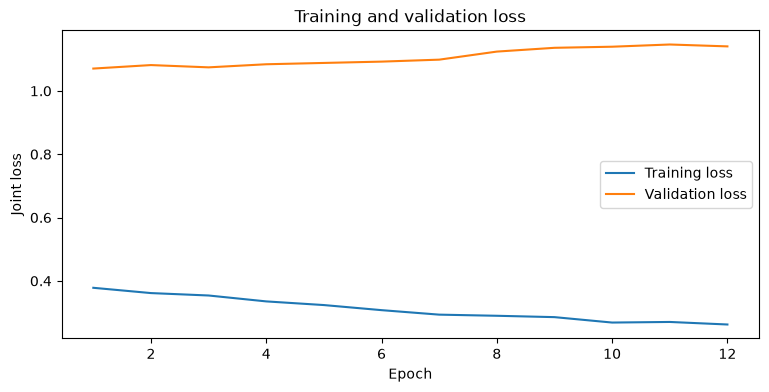

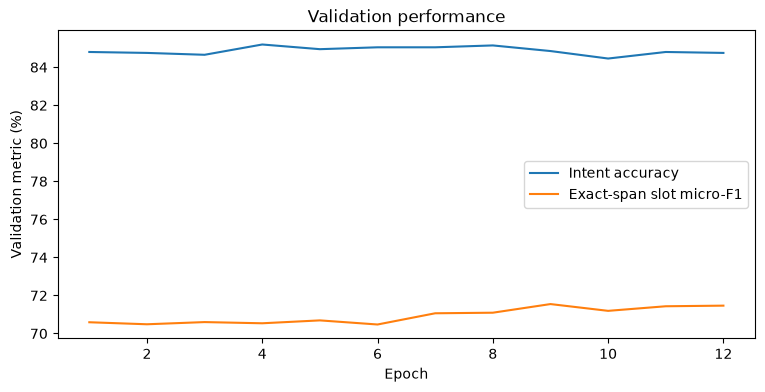

In [13]:
epoch_numbers = [entry["epoch"] for entry in training_history]

plt.figure(figsize=(9, 4))
plt.plot(epoch_numbers, [entry["training_loss"] for entry in training_history], label="Training loss")
plt.plot(epoch_numbers, [entry["validation_loss"] for entry in training_history], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Joint loss")
plt.title("Training and validation loss")
plt.legend()
plt.show()

plt.figure(figsize=(9, 4))
plt.plot(epoch_numbers, [entry["intent_accuracy"] for entry in training_history], label="Intent accuracy")
plt.plot(epoch_numbers, [entry["slot_micro_f1"] for entry in training_history], label="Exact-span slot micro-F1")
plt.xlabel("Epoch")
plt.ylabel("Validation metric (%)")
plt.title("Validation performance")
plt.legend()
plt.show()

## 12. Reload the saved checkpoint and evaluate

The weights remaining in memory belong to the **last epoch**, not necessarily the best one. This cell reloads the selected checkpoint, verifies its validation score, and **then** runs the final test evaluation. Do not tune the model using test results.

In [14]:
saved_checkpoint = torch.load(checkpoint_file_path, map_location=device, weights_only=True)
best_model = JointBiLSTM(**saved_checkpoint["model_settings"]).to(device)
best_model.load_state_dict(saved_checkpoint["model_weights"])

final_validation_results = evaluate_model(best_model, validation_loader)
reloaded_validation_score = (
    final_validation_results["intent_accuracy"] + final_validation_results["slot_micro_f1"]
) / 2
assert abs(reloaded_validation_score - saved_checkpoint["best_validation_score"]) < 0.00001

print("Validation intent accuracy:", f"{final_validation_results['intent_accuracy']:.2f}%")
print("Validation slot micro-F1:", f"{final_validation_results['slot_micro_f1']:.2f}%")

final_test_results = evaluate_model(best_model, test_loader)
print("Test intent accuracy:", f"{final_test_results['intent_accuracy']:.2f}%")
print("Test slot micro-F1:", f"{final_test_results['slot_micro_f1']:.2f}%")

print("Sample prediction errors:")
for prediction_error in final_test_results["errors"][:5]:
    print(prediction_error)

Validation intent accuracy: 84.85%
Validation slot micro-F1: 71.55%
Test intent accuracy: 83.96%
Test slot micro-F1: 68.60%
Sample prediction errors:
{'utterance': 'pink is all we need', 'correct_intent': 'iot_hue_lightchange', 'predicted_intent': 'lists_query', 'correct_slots': [('color_type', 'pink')], 'predicted_slots': [('artist_name', 'pink')]}
{'utterance': 'and the darkness has fallen', 'correct_intent': 'iot_hue_lighton', 'predicted_intent': 'weather_query', 'correct_slots': [], 'predicted_slots': []}
{'utterance': "it's dirty here make some noise", 'correct_intent': 'iot_cleaning', 'predicted_intent': 'play_music', 'correct_slots': [], 'predicted_slots': []}
{'utterance': 'hoover the hallway', 'correct_intent': 'iot_cleaning', 'predicted_intent': 'iot_cleaning', 'correct_slots': [('house_place', 'hallway')], 'predicted_slots': []}
{'utterance': 'i want the status on my screen brightness', 'correct_intent': 'general_quirky', 'predicted_intent': 'social_post', 'correct_slots': [

## Save the trained model manually

The training loop already saves the **best validation checkpoint** to `bilstm_joint_best.pt`.

This optional cell creates a second, clearly named model file after the best checkpoint has been reloaded. It saves the model weights, architecture configuration, vocabulary and label mappings, plus training history, so you can load it in another notebook without retraining.

Run this **after Section 12**. If you have not run training and checkpoint loading, this cell will not work.

In [ ]:
from pathlib import Path
import torch

# Save the best model that was reloaded and evaluated in Section 12.
model_save_path = Path("joint_bilstm_trained_model.pt")

model_package = {
    "model_weights": best_model.state_dict(),
    "model_settings": model_settings,
    "word_to_id": word_to_id,
    "intent_to_id": intent_to_id,
    "slot_to_id": slot_to_id,
    "training_history": training_history,
    "best_epoch": best_epoch_number,
    "best_validation_score": best_validation_score,
}

torch.save(model_package, model_save_path)

print("Model saved to:", model_save_path.resolve())
print("File size (MB):", round(model_save_path.stat().st_size / (1024 * 1024), 2))

## 13. Predict on a new utterance

At inference time the model receives **only the sentence**. It does not receive its true intent, annotated sentence, or scenario. We tokenize the sentence, translate words to IDs, run the selected checkpoint, and convert BIO tags back into readable slot spans.

In [15]:
@torch.no_grad()
def predict_sentence(utterance, trained_model, saved_checkpoint):
    token_offsets = tokenize_with_offsets(utterance)
    if not token_offsets:
        raise ValueError("Enter a sentence containing at least one word")

    saved_word_to_id = saved_checkpoint["word_to_id"]
    saved_id_to_intent = {
        intent_index: label
        for label, intent_index in saved_checkpoint["intent_to_id"].items()
    }
    saved_id_to_slot = {
        slot_index: label
        for label, slot_index in saved_checkpoint["slot_to_id"].items()
    }

    word_ids = [
        saved_word_to_id.get(token.lower(), saved_word_to_id["<UNK>"])
        for token, token_start, token_end in token_offsets
    ]
    input_word_ids = torch.tensor([word_ids], device=device)
    sequence_lengths = torch.tensor([len(word_ids)])

    trained_model.eval()
    intent_scores, slot_scores = trained_model(input_word_ids, sequence_lengths)
    predicted_intent_id = int(intent_scores.argmax(dim=-1).item())
    predicted_slot_ids = slot_scores.argmax(dim=-1)[0].tolist()
    predicted_bio_labels = [saved_id_to_slot[slot_id] for slot_id in predicted_slot_ids]
    character_offsets = [(start, end) for token, start, end in token_offsets]
    predicted_slot_pairs = decode_slot_spans(predicted_bio_labels, character_offsets, utterance)

    return {
        "intent": saved_id_to_intent[predicted_intent_id],
        "slots": [
            {"type": slot_type, "span": slot_text}
            for slot_type, slot_text in predicted_slot_pairs
        ],
    }

print(predict_sentence("wake me up at nine am on friday", best_model, saved_checkpoint))

{'intent': 'alarm_set', 'slots': [{'type': 'time', 'span': 'nine am'}, {'type': 'date', 'span': 'friday'}]}


## 14. Important assumptions and troubleshooting

- **This is a learning reference, not independently developed Stage 1 code.** Use it consistently with your assignment's AI-collaboration rules.
- **Slot alignment:** the whitespace tokenizer assumes the official slot boundaries match whitespace-delimited tokens. If a record fails alignment, inspect the record and consider a more precise tokenizer rather than dropping it.
- **Slot inventory:** every slot type is collected from training annotations. Both `B-` and `I-` tags are generated for each one; completely unseen slot types still require separate investigation.
- **Checkpoint metrics:** the assignment evaluates exact `[slot type, slot span]` matches across records. The scorer above compares type + literal span text and uses a `Counter` to handle repeats within one utterance.
- **CUDA:** if you receive a DLL or GPU error, first confirm that your notebook has the correct Anaconda kernel and CUDA-enabled PyTorch installation.
- **Stateful Jupyter cells:** rerun from the top after making changes so old variable values do not remain in memory.
- **Reproducibility:** keep the actual cell outputs, learning curves, checkpoint metadata, and training logs; do not fabricate or type scores manually.

In [1]:
trainable_parameter_count = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print(f"Total parameters: {model_parameter_count:,}")
print(f"Trainable parameters: {trainable_parameter_count:,}")
print(f"Parameter limit: {20_000_000:,}")

NameError: name 'model' is not defined